In [88]:
from ISLP import load_data
from ISLP.models import ModelSpec
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = load_data('Auto').reset_index() # fixes the fact that the names were acting as indexes. now its a seperate column
df.head()

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
1,buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
2,plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
3,amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
4,ford torino,17.0,8,302.0,140,3449,10.5,70,1


In [ ]:
X = sm.add_constant(df['horsepower'])  # adds intercept 1
y = df['mpg']

model = sm.OLS(y, X).fit()
    
print(model.summary())
print(model.params)

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Mon, 04 Aug 2025   Prob (F-statistic):           7.03e-81
Time:                        17:48:32   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.9359      0.717     55.660      0.0

the R-squared value is 60% which is not good. intercept is 39.9 and slope is -0.15

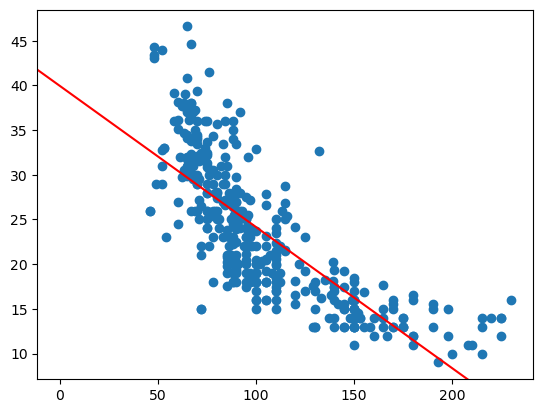

In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.scatter(df['horsepower'], df['mpg'], label='Data')

intercept, slope = model.params
ax.axline(xy1=(0, intercept), slope=slope, color='red', label='OLS Regression');

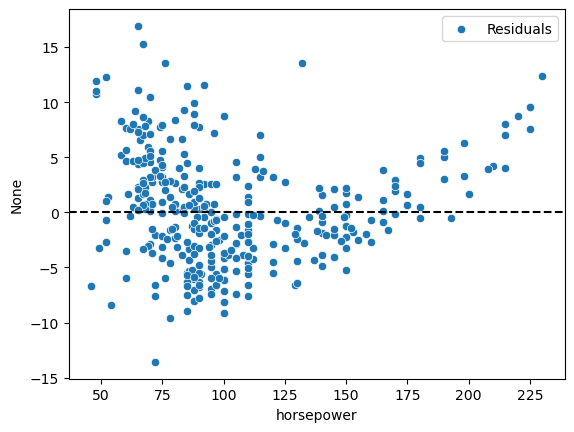

In [54]:
sns.scatterplot(data=df, x= 'horsepower', y= y - model.predict(X), label='Residuals')
plt.axhline(y=0, color='black', linestyle='--');

In [ ]:
new_X = pd.DataFrame({'const': 1, 'horsepower': [98]})
predictions = model.get_prediction(new_X)
pred_summary = predictions.summary_frame(alpha=0.05)
pred_summary

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,24.467077,0.251262,23.973079,24.961075,14.809396,34.124758


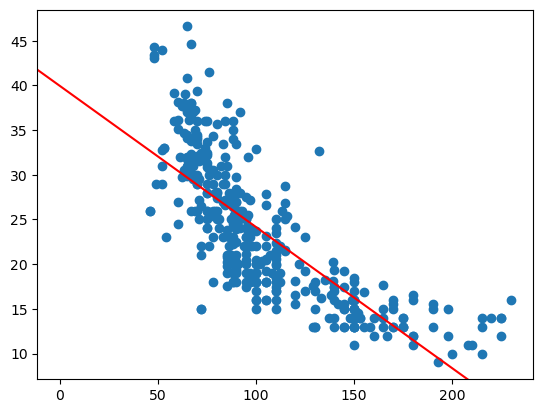

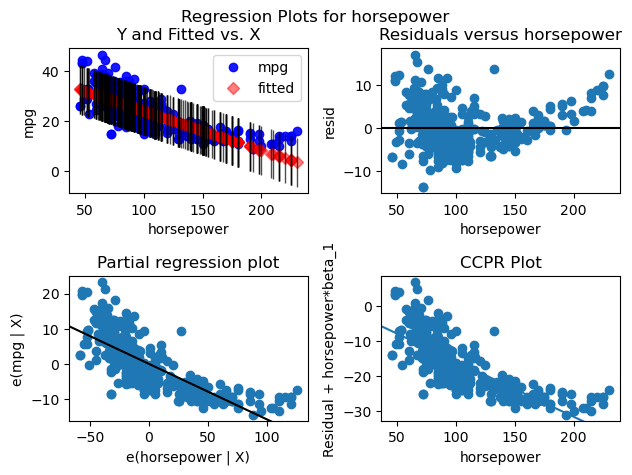

In [9]:
sm.graphics.plot_regress_exog(model, 'horsepower')
plt.show()

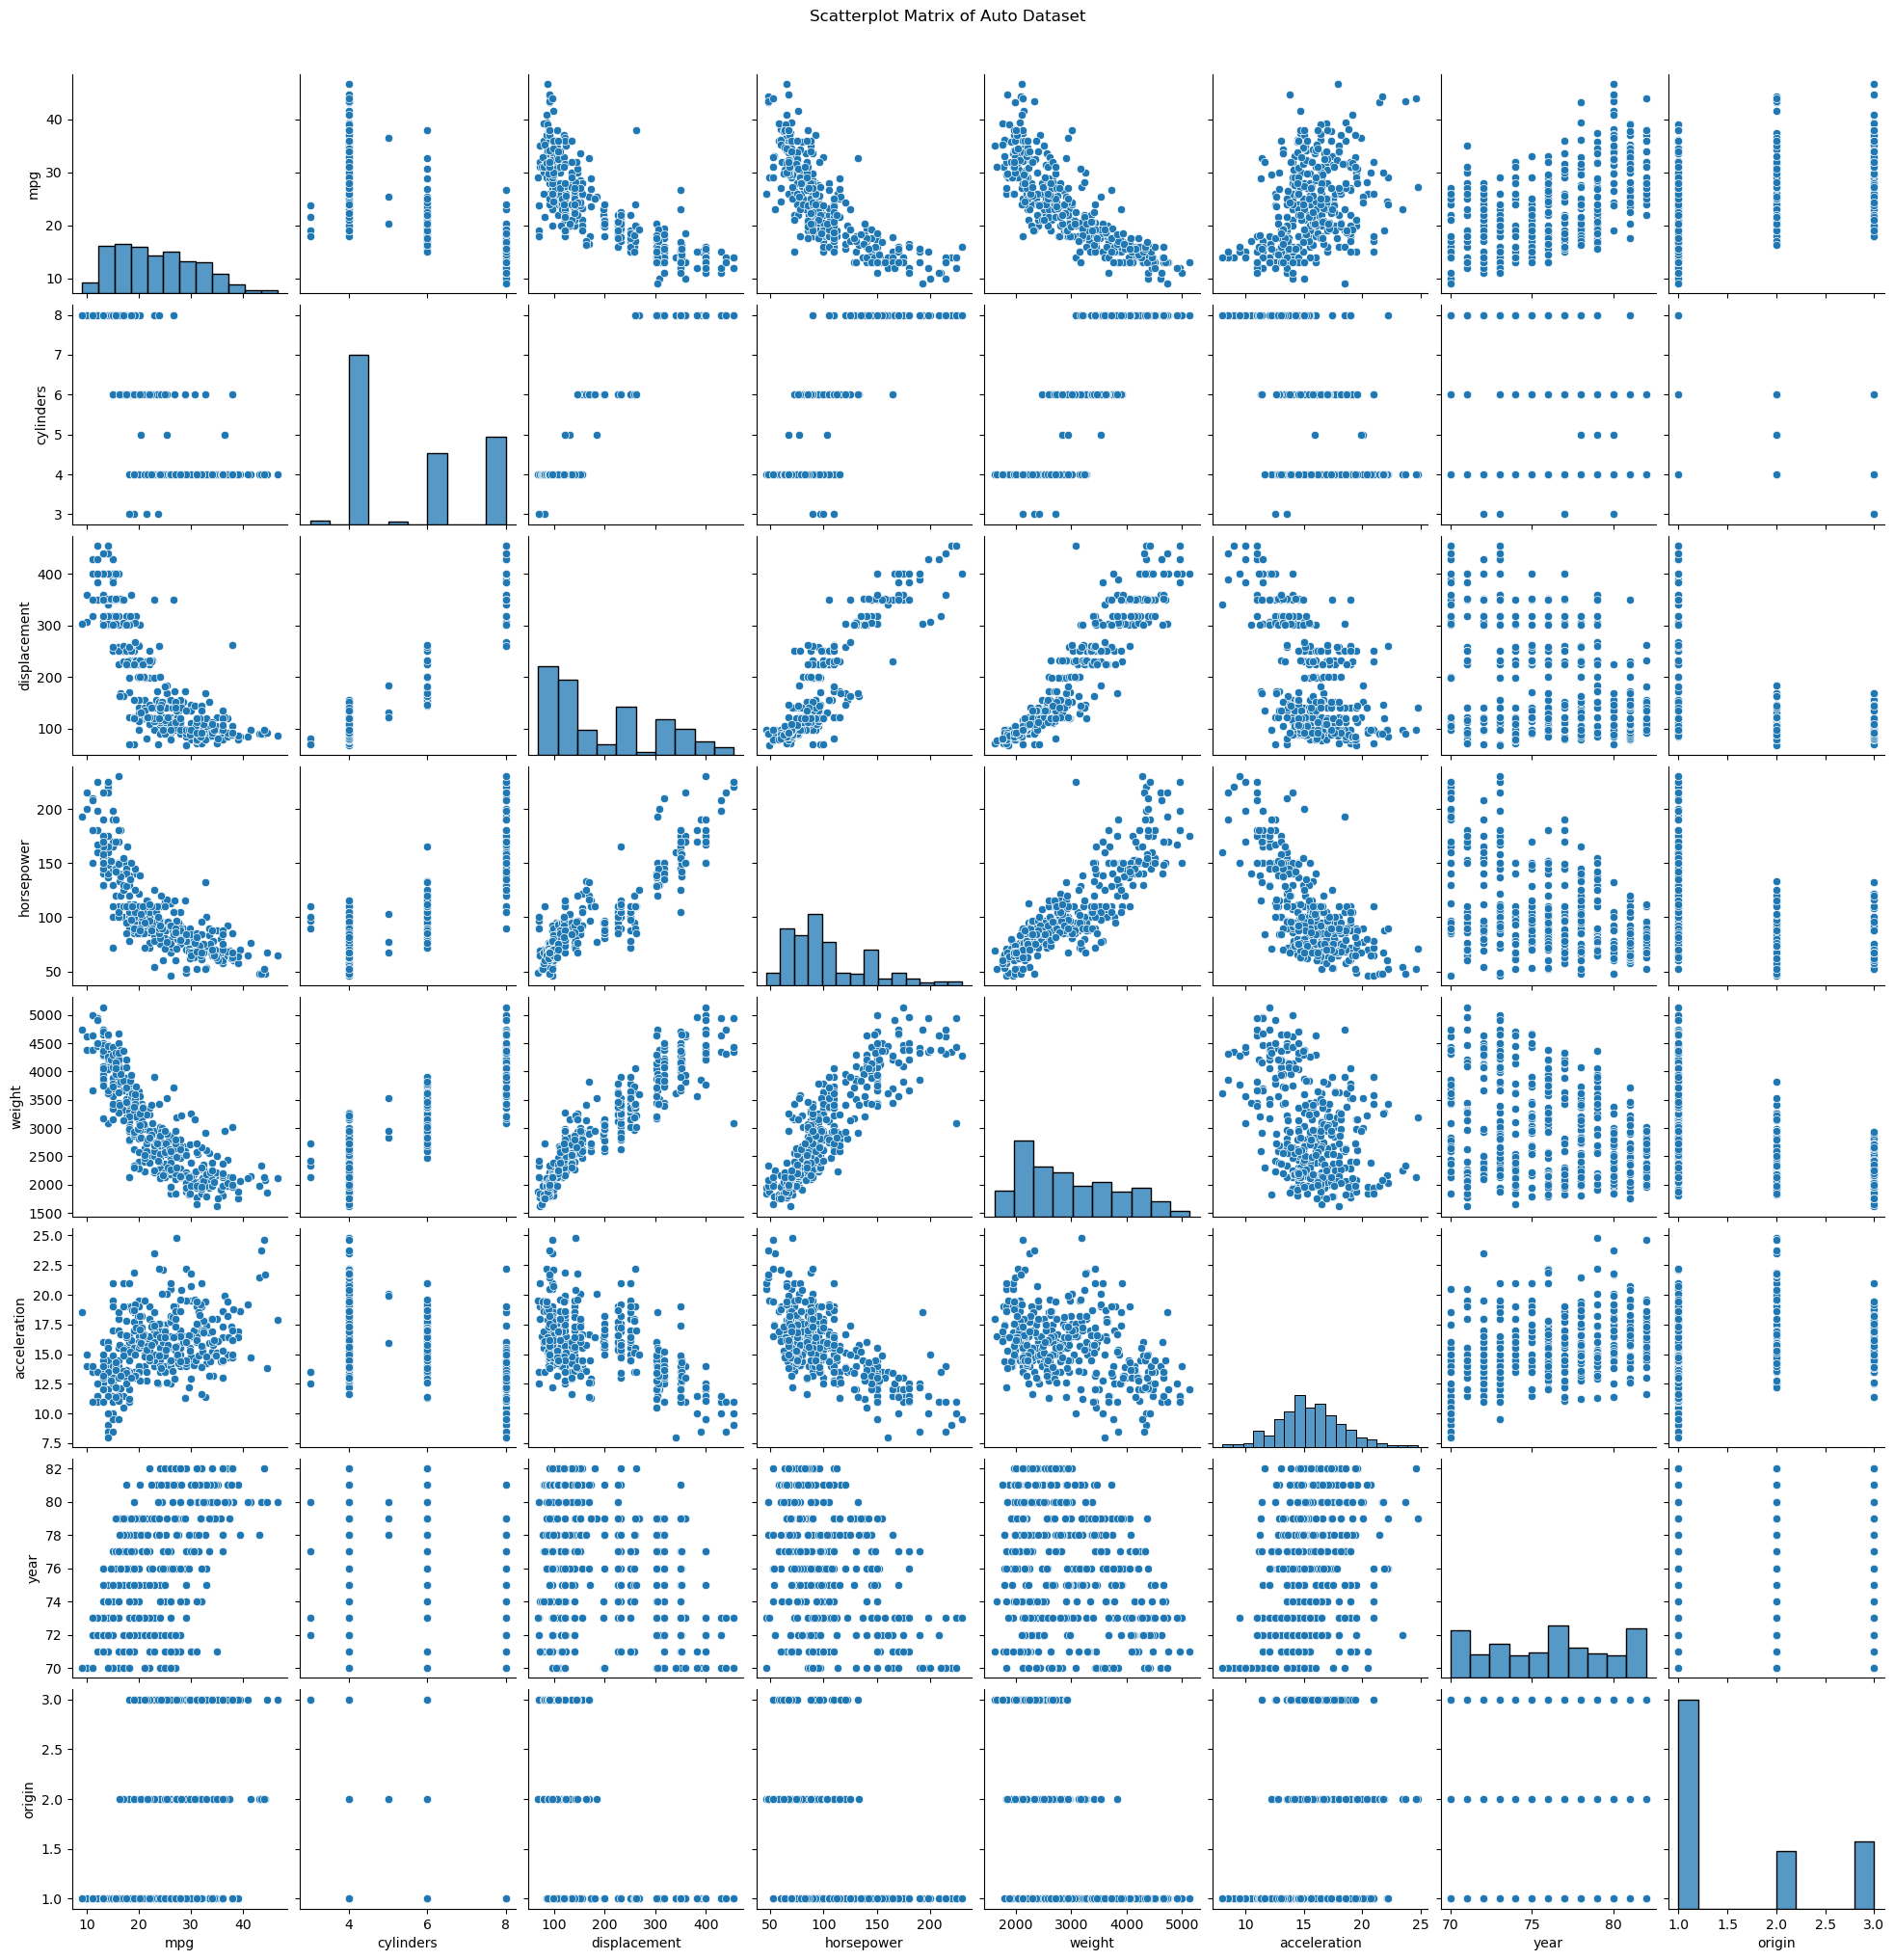

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
from ISLP import load_data

# Drop non-numeric column for now
df_numeric = df.drop(columns='name')

# Pairplot (scatterplot matrix)
sns.pairplot(df_numeric)
plt.suptitle("Scatterplot Matrix of Auto Dataset", y=1.02)
plt.show()

In [18]:
# Correlation matrix
corr_matrix = df_numeric.corr()
print(corr_matrix)

                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.777618     -0.805127   -0.778427 -0.832244   
cylinders    -0.777618   1.000000      0.950823    0.842983  0.897527   
displacement -0.805127   0.950823      1.000000    0.897257  0.932994   
horsepower   -0.778427   0.842983      0.897257    1.000000  0.864538   
weight       -0.832244   0.897527      0.932994    0.864538  1.000000   
acceleration  0.423329  -0.504683     -0.543800   -0.689196 -0.416839   
year          0.580541  -0.345647     -0.369855   -0.416361 -0.309120   
origin        0.565209  -0.568932     -0.614535   -0.455171 -0.585005   

              acceleration      year    origin  
mpg               0.423329  0.580541  0.565209  
cylinders        -0.504683 -0.345647 -0.568932  
displacement     -0.543800 -0.369855 -0.614535  
horsepower       -0.689196 -0.416361 -0.455171  
weight           -0.416839 -0.309120 -0.585005  
acceleration      1.000000  0.290316  0.212746  

1-degree train score: 0.5955625946891978
1-degree test score: 0.6456234296465987
2-degree train score: 0.6731244766416671
2-degree test score: 0.7423728822799187
3-degree train score: 0.6829685937334211
3-degree test score: 0.7481691722739237


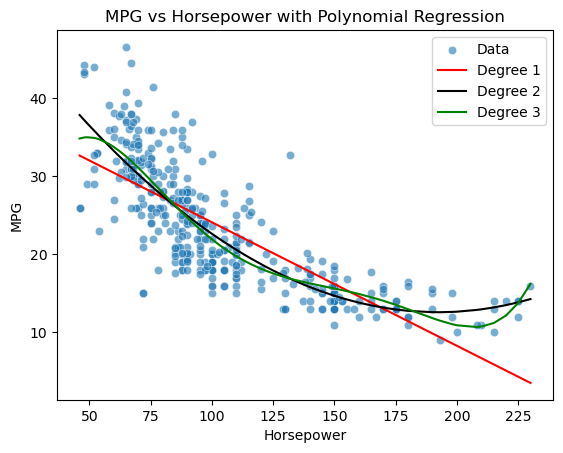

In [182]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

X = df[['horsepower']]
y = df[['mpg']]

sns.scatterplot(data=df, x='horsepower', y='mpg', alpha=0.6, label='Data')

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
d1_model = LinearRegression()
d1_model.fit(x_train, y_train)

print('1-degree train score:', d1_model.score(x_train, y_train))
print('1-degree test score:', d1_model.score(x_test, y_test))
X_sorted = X.sort_values(by='horsepower')
plt.plot(X_sorted, d1_model.predict(X_sorted), color='red', label='Degree 1', zorder = 2)

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

x_train, x_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=0)
d2_model = LinearRegression()
d2_model.fit(x_train, y_train)

print('2-degree train score:', d2_model.score(x_train, y_train))
print('2-degree test score:', d2_model.score(x_test, y_test))
X_poly_sorted = poly.transform(X_sorted)
plt.plot(X_sorted, d2_model.predict(X_poly_sorted), color='black', label='Degree 2', zorder = 3)

poly = PolynomialFeatures(degree=5)
X_poly3 = poly.fit_transform(X)

x_train, x_test, y_train, y_test = train_test_split(X_poly3, y, test_size=0.2, random_state=0)
d3_model = LinearRegression()
d3_model.fit(x_train, y_train)

print('3-degree train score:', d3_model.score(x_train, y_train))
print('3-degree test score:', d3_model.score(x_test, y_test))
X_poly_sorted = poly.transform(X_sorted)
plt.plot(X_sorted, d3_model.predict(X_poly_sorted), color='green', label='Degree 3', zorder = 4)

plt.legend()
plt.title('MPG vs Horsepower with Polynomial Regression')
plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.show()

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(8, 10))

residuals = (y - d1_model.predict(X)).iloc[:, 0]
sns.scatterplot(ax=ax[0], x=X['horsepower'], y=residuals.values, alpha=0.6)
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_title('Residuals vs Horsepower (Degree 1)')

residuals = y.values - d2_model.predict(X_poly)
sns.scatterplot(ax=ax[1], x=X['horsepower'].values, y=residuals.squeeze())
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title('Residuals vs Fitted (Degree 2)');

<Axes: xlabel='horsepower'>

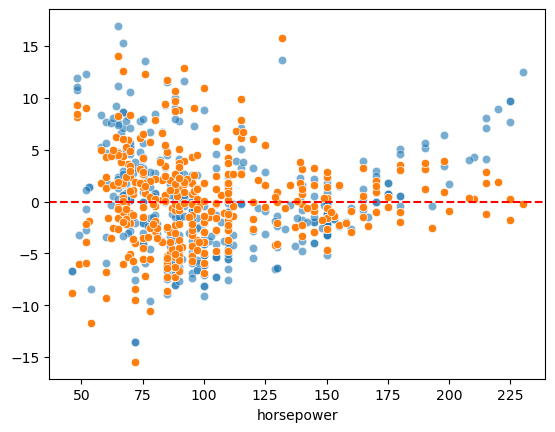

In [186]:
# fig, ax = plt.subplots(2, 1, figsize=(8, 10))

residuals = (y - d1_model.predict(X)).iloc[:, 0]
sns.scatterplot(x=X['horsepower'], y=residuals.values, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
# ax[0].set_title('Residuals vs Horsepower (Degree 1)')

# residuals = y.values - d2_model.predict(X_poly)
# sns.scatterplot(x=X['horsepower'].values, y=residuals.squeeze())
# ax[1].axhline(0, color='red', linestyle='--')
# ax[1].set_title('Residuals vs Fitted (Degree 2)');

residuals = y.values - d3_model.predict(X_poly3)
sns.scatterplot(x=X['horsepower'].values, y=residuals.squeeze())
